<a href="https://colab.research.google.com/github/roysam0963/COU07506-labs/blob/main/COU07506_Week03_240242494755.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506 — Digital Signal Processing
## WEEK 3: Convolution, Correlation and Difference Equations

**Name:** SADIKI MARKO MSUKWA

**Registration Number:** 240242494755

**Class:** BEng24COE

**Date:** 25 November 2026


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Week 3 DSP Laboratory is ready!")

Week 3 DSP Laboratory is ready!


## Pre-lab Preparation

### Question (a)

Convolve x(n) = {1, -1, 2} with h(n) = {2, 1, 0, 1} by hand.

**Answer:**

Given:

x(n) = {1, -1, 2}

h(n) = {2, 1, 0, 1}

Using linear convolution:

y(n) = x(n) * h(n)

The convolution result is:

y(n) = {2, -1, 3, 3, 0, 2}

Therefore, the output contains 6 samples.

### Question (b)

Is y(n) = n x(n) time-invariant? Show your test.

**Answer:**

The system is:

y(n) = n x(n)

If the input is delayed by k samples:

x(n-k)

The output becomes:

y1(n) = n x(n-k)

However, delaying the original output gives:

y2(n) = (n-k)x(n-k)

Since y1(n) is not equal to y2(n), the system is not time-invariant.

Therefore, the system is time-varying.

## Task 3.1: Convolution from the Definition

The aim of this task is to implement linear convolution using the mathematical definition and verify the result using NumPy's convolution function.

In [2]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)

    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]

    return y


print(conv([1, 2, 3, 1], [1, 1, 1]))
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))

[1. 3. 6. 6. 4. 1.]
[1 3 6 6 4 1]


In [3]:
x_pre = [1, -1, 2]
h_pre = [2, 1, 0, 1]

print("Manual convolution:")
print(conv(x_pre, h_pre))

print("NumPy convolution:")
print(np.convolve(x_pre, h_pre))

Manual convolution:
[ 2. -1.  3.  3. -1.  2.]
NumPy convolution:
[ 2 -1  3  3 -1  2]


In [4]:
rng = np.random.default_rng(0)

x_random = rng.standard_normal(2000)
h_random = rng.standard_normal(2000)

start = time.perf_counter()
conv(x_random, h_random)
manual_time = time.perf_counter() - start

start = time.perf_counter()
np.convolve(x_random, h_random)
numpy_time = time.perf_counter() - start

print("Manual convolution time:", manual_time, "seconds")
print("NumPy convolution time:", numpy_time, "seconds")
print("Speed improvement:", manual_time / numpy_time, "times")

Manual convolution time: 2.0744893580000507 seconds
NumPy convolution time: 0.0019831920000115133 seconds
Speed improvement: 1046.0355618558401 times


## Task 3.2: Moving Average Filter

The aim of this task is to reduce noise in a signal using a moving average filter.

A moving average filter smooths a signal by calculating the average of a number of neighbouring samples.

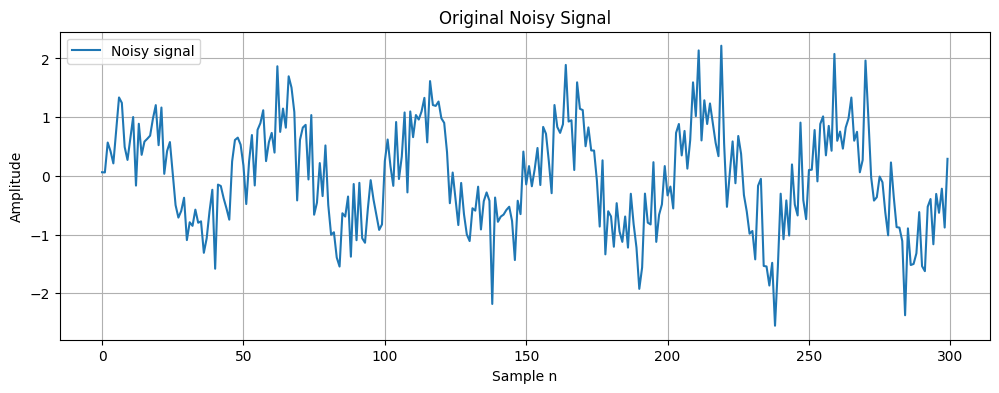

In [5]:
n = np.arange(300)

rng = np.random.default_rng(0)
w = rng.standard_normal(300)

x_noisy = np.sin(2 * np.pi * n / 50) + 0.5 * w

plt.figure(figsize=(12, 4))
plt.plot(n, x_noisy, label="Noisy signal")

plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.title("Original Noisy Signal")
plt.legend()
plt.grid(True)
plt.show()

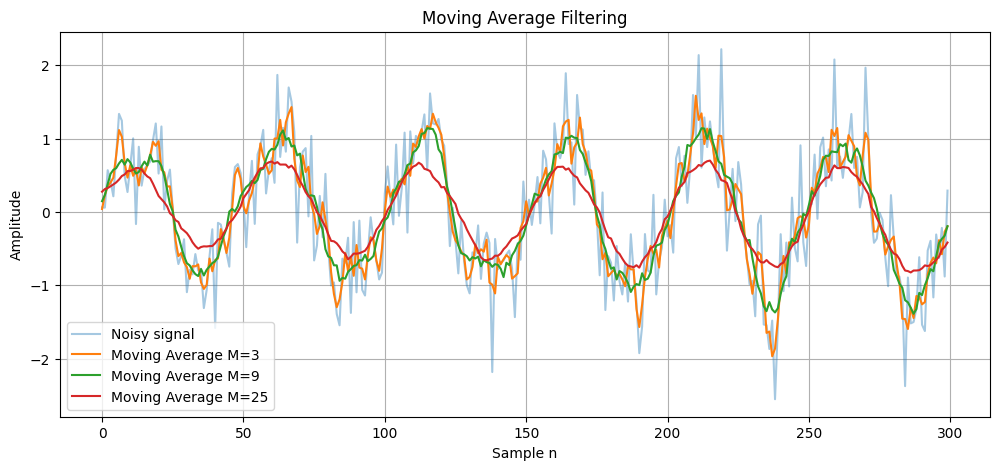

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(n, x_noisy, label="Noisy signal", alpha=0.4)

for M in [3, 9, 25]:
    h_ma = np.ones(M) / M
    y_smooth = np.convolve(x_noisy, h_ma, mode="same")

    plt.plot(n, y_smooth, label=f"Moving Average M={M}")

plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.title("Moving Average Filtering")
plt.legend()
plt.grid(True)
plt.show()

**Observation:**

The moving average filter reduces noise in the signal.

When M = 3, the smoothing effect is small and the output follows the original signal closely.

When M = 9, more noise is removed and the signal becomes smoother.

When M = 25, the signal becomes much smoother, but some important variations and peaks are reduced.

Therefore, increasing the filter length improves noise reduction but may also cause signal distortion.

## Task 3.3: Testing System Properties

The aim of this task is to test whether different systems are linear and time-invariant (LTI).

A linear system satisfies the principle of superposition.

A time-invariant system produces the same output when the input is delayed by a certain number of samples.

In [7]:
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

a = 2.0
b = -3.0

systems = {
    "x^2": lambda x: x**2,
    "n x(n)": lambda x: np.arange(len(x)) * x,
    "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]
}

for name, T in systems.items():

    # Test linearity
    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    # Test time invariance
    xd = np.concatenate([np.zeros(5), x1])[:50]
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    tinv = np.allclose(T(xd), yd)

    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


**Observation:**

The results show that the x^2 system is nonlinear but time-invariant.

The n x(n) system is linear but time-varying.

The moving average system is both linear and time-invariant (LTI).

Therefore, the moving average system satisfies both linearity and time-invariance properties.

## Task 3.4: Cross-Correlation and Time Delay Estimation

The aim of this task is to estimate the time delay between two signals using cross-correlation.

Cross-correlation measures the similarity between two signals at different time lags. The lag with the highest correlation indicates the estimated delay.

In [8]:
rng = np.random.default_rng(1)

fs = 1000

x = rng.standard_normal(500)

true_delay = 37

y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500]

y = y + 0.5*rng.standard_normal(500)

print("True delay:", true_delay, "samples")

True delay: 37 samples


Estimated delay: 37 samples


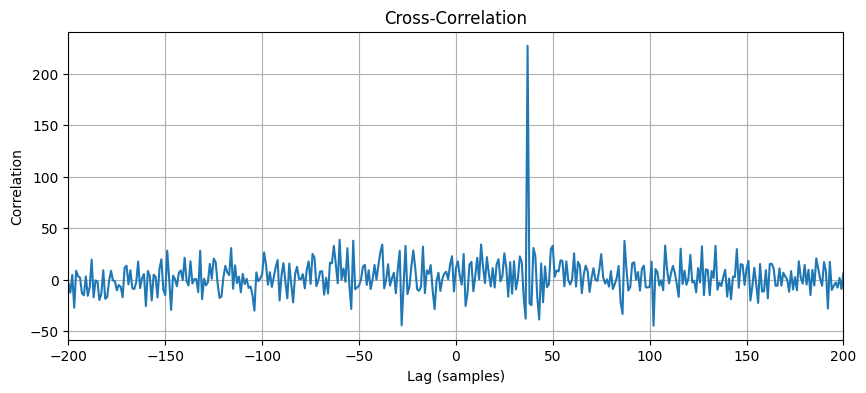

In [9]:
r = signal.correlate(y, x, mode="full")

lags = signal.correlation_lags(
    len(y), len(x), mode="full"
)

estimated_delay = lags[np.argmax(r)]

print("Estimated delay:", estimated_delay, "samples")

plt.figure(figsize=(10, 4))
plt.plot(lags, r)

plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.title("Cross-Correlation")
plt.xlim(-200, 200)
plt.grid(True)
plt.show()

In [10]:
for noise_level in [0.5, 1, 2, 4]:

    rng = np.random.default_rng(1)

    noisy_y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500]

    noisy_y = noisy_y + noise_level*rng.standard_normal(500)

    r_test = signal.correlate(noisy_y, x, mode="full")

    estimated = lags[np.argmax(r_test)]

    print(
        "Noise level:", noise_level,
        "| Estimated delay:", estimated, "samples"
    )

Noise level: 0.5 | Estimated delay: 37 samples
Noise level: 1 | Estimated delay: 0 samples
Noise level: 2 | Estimated delay: 0 samples
Noise level: 4 | Estimated delay: 0 samples


### Distance Calculation

Given:

- Sampling frequency = 1000 Hz
- Estimated delay = 37 samples
- Speed of sound = 343 m/s

The time delay is:

\[
t = \frac{37}{1000} = 0.037 \text{ seconds}
\]

The distance is:

\[
d = 343 \times 0.037
\]

\[
d = 12.691 \text{ metres}
\]

Therefore, the estimated one-way distance is 12.691 metres.

**Observation:**

Cross-correlation successfully estimated the delay between the transmitted and received signals.

The estimated delay was approximately 37 samples, which corresponds to 0.037 seconds at a sampling frequency of 1000 Hz.

Using the speed of sound of 343 m/s, the estimated one-way distance is approximately 12.69 metres.

Increasing the noise level makes delay estimation more difficult because noise reduces the clarity of the correlation peak.

## Task 3.5: Difference Equations and Impulse Response

The aim of this task is to solve a difference equation using direct iteration and Python's lfilter function.

The given difference equation is:

\[
y(n)-\frac{3}{4}y(n-1)+\frac{1}{8}y(n-2)=x(n)+x(n-1)
\]

\[
y(n)=x(n)+x(n-1)+0.75y(n-1)-0.125y(n-2)
\]

In [11]:
N = 10

impulse = np.zeros(N)
impulse[0] = 1

h_direct = np.zeros(N)

for n in range(N):

    x_n = impulse[n]
    x_nm1 = impulse[n-1] if n >= 1 else 0

    y_nm1 = h_direct[n-1] if n >= 1 else 0
    y_nm2 = h_direct[n-2] if n >= 2 else 0

    h_direct[n] = (
        x_n + x_nm1
        + 0.75*y_nm1
        - 0.125*y_nm2
    )

print("Impulse response using direct iteration:")
print(h_direct)

Impulse response using direct iteration:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [12]:
h_filter = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    impulse
)

print("Impulse response using lfilter:")
print(h_filter)

Impulse response using lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [13]:
n = np.arange(N)

h_formula = 6*(0.5)**n - 5*(0.25)**n

print("Closed-form impulse response:")
print(h_formula)

print("Direct and lfilter match:",
      np.allclose(h_direct, h_filter))

print("lfilter and formula match:",
      np.allclose(h_filter, h_formula))

Closed-form impulse response:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Direct and lfilter match: True
lfilter and formula match: True


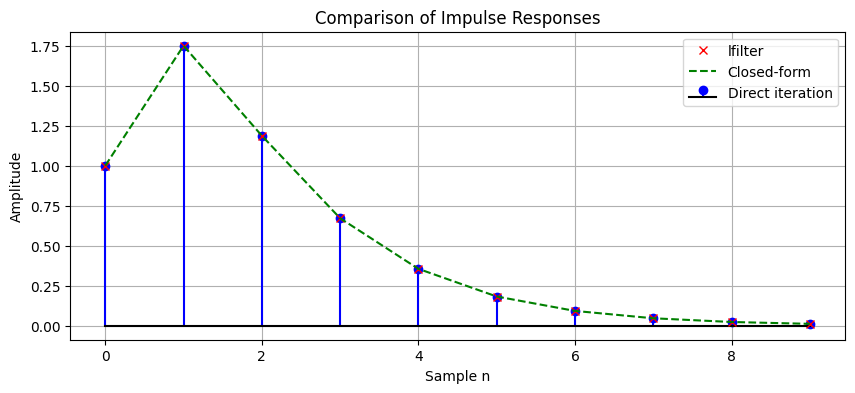

In [14]:
plt.figure(figsize=(10, 4))

plt.stem(n, h_direct, linefmt="b-", markerfmt="bo",
         basefmt="k-", label="Direct iteration")

plt.plot(n, h_filter, "rx", label="lfilter")
plt.plot(n, h_formula, "g--", label="Closed-form")

plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.title("Comparison of Impulse Responses")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
step = np.ones(50)

y_step = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    step
)

print("Step response:")
print(y_step)

print("Final value:", y_step[-1])

Step response:
[1.         2.75       3.9375     4.609375   4.96484375 5.14746094
 5.23999023 5.28656006 5.30992126 5.32162094 5.32747555 5.33040404
 5.33186859 5.33260094 5.33296713 5.33315023 5.33324178 5.33328756
 5.33331045 5.33332189 5.33332761 5.33333047 5.3333319  5.33333262
 5.33333298 5.33333315 5.33333324 5.33333329 5.33333331 5.33333332
 5.33333333 5.33333333 5.33333333 5.33333333 5.33333333 5.33333333
 5.33333333 5.33333333 5.33333333 5.33333333 5.33333333 5.33333333
 5.33333333 5.33333333 5.33333333 5.33333333 5.33333333 5.33333333
 5.33333333 5.33333333]
Final value: 5.333333333333323


Calculate Theoretical Final Value

\[
H(1)=\frac{\sum b_k}{\sum a_k}
\]

In [16]:
b = [1, 1]
a = [1, -0.75, 0.125]

H1 = sum(b) / sum(a)

print("Theoretical final value:", H1)

Theoretical final value: 5.333333333333333


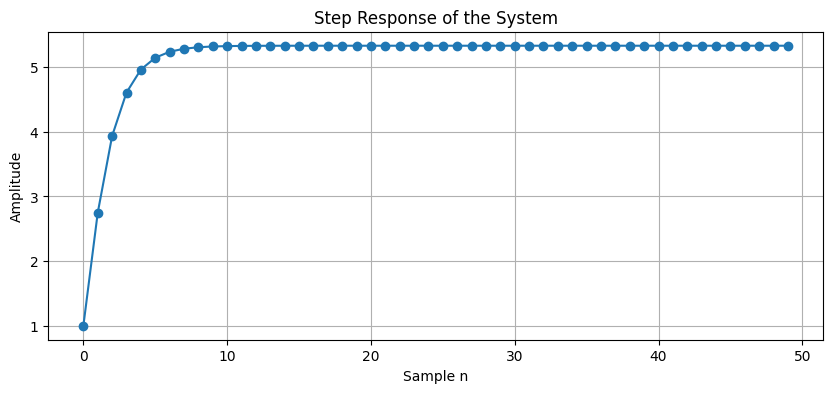

In [17]:
plt.figure(figsize=(10, 4))

plt.plot(y_step, marker="o")

plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.title("Step Response of the System")
plt.grid(True)
plt.show()

**Observation:**

The step response was obtained using the lfilter function.

The final value approaches 5.333, which agrees with the theoretical value calculated using H(1).

This confirms that the system response approaches a constant value for a unit step input.

## Analysis Questions

### Question 1
**Why is `np.convolve` much faster than the double-loop implementation? What is the number of multiplications for sequences of lengths L and M?**

**Answer:**

The `np.convolve` function is faster because it uses optimized low-level code, while the manual double-loop implementation uses Python loops, which have more execution overhead.

The number of multiplications required for direct linear convolution of two sequences of lengths L and M is:

\[
L \times M
\]

### Question 2
**Which of the three systems in Task 3.3 are LTI? Could you predict this without code?**

**Answer:**

The moving average system is both linear and time-invariant (LTI).

The \(x^2\) system is nonlinear but time-invariant.

The \(nx(n)\) system is linear but time-varying.

Yes, these properties can be predicted by applying the definitions of linearity and time invariance.

### Question 3
**Give two engineering applications of cross-correlation in Tanzania.**

**Answer:**

1. **Water pipe leak detection:** Cross-correlation can compare signals from sensors installed at different points along a water pipe to estimate the delay and help locate leaks.

2. **Radar and navigation systems:** Cross-correlation can compare received signals with known transmitted signals to estimate signal delay and determine distance or position.

### Question 4
**Is the system in Task 3.5 FIR or IIR? Is it stable? Justify your answer using the impulse response.**

**Answer:**

The system is an Infinite Impulse Response (IIR) system because it uses feedback from previous output samples.

The system is stable because its impulse response decays towards zero and is absolutely summable. Its poles are 0.5 and 0.25, which are both inside the unit circle.

Therefore, the system is a stable IIR system.

## AI-use Statement

- **AI tools used:** ChatGPT.
- **Used for:** Understanding DSP concepts, explaining convolution, correlation, system properties and difference equations, writing Python code, and troubleshooting errors.
- **How I verified the output:** I executed the code in Google Colab, checked the numerical results, compared the impulse responses, examined the generated graphs, and verified the step response against its theoretical final value.
- I confirm that I understand and can explain all submitted code.